Model Valid: True


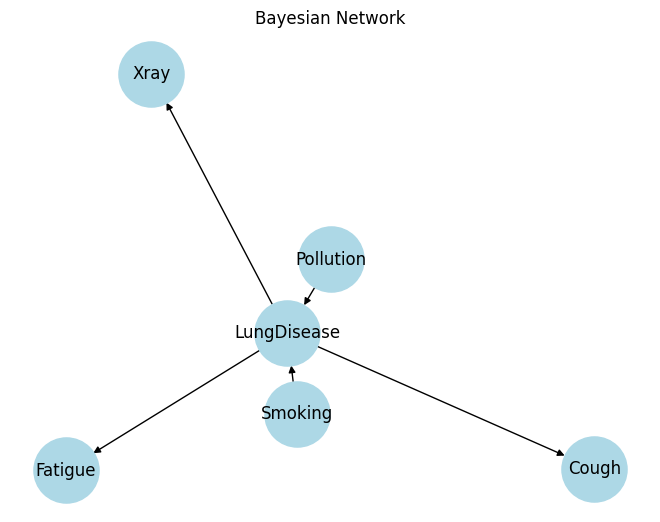

In [13]:

!pip -q install pgmpy

import networkx as nx
import matplotlib.pyplot as plt

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

model = DiscreteBayesianNetwork([
    ("Smoking", "LungDisease"),
    ("Pollution", "LungDisease"),
    ("LungDisease", "Cough"),
    ("LungDisease", "Xray"),
    ("LungDisease", "Fatigue")
])

cpds = [
    TabularCPD("Smoking", 2, [[.7], [.3]]),

    TabularCPD("Pollution", 2, [[.6], [.4]]),

    TabularCPD(
        "LungDisease", 2,
        [[.99, .9, .9, .2],
         [.01, .1, .1, .8]],
        evidence=["Smoking", "Pollution"],
        evidence_card=[2, 2]
    ),

    TabularCPD(
        "Cough", 2,
        [[.8, .2], [.2, .8]],
        evidence=["LungDisease"],
        evidence_card=[2]
    ),

    TabularCPD(
        "Xray", 2,
        [[.95, .1], [.05, .9]],
        evidence=["LungDisease"],
        evidence_card=[2]
    ),

    TabularCPD(
        "Fatigue", 2,
        [[.7, .3], [.3, .7]],
        evidence=["LungDisease"],
        evidence_card=[2]
    )
]

model.add_cpds(*cpds)

print("Model Valid:", model.check_model())

G = nx.DiGraph(model.edges())

nx.draw(
    G,
    nx.spring_layout(G, seed=2),
    with_labels=True,
    node_color="lightblue",
    node_size=2200,
    arrows=True
)

plt.title("Bayesian Network")
plt.show()
